# Gain measurement
Fit gain results to Polya distribution
$$
f(G;\bar{G},\theta) = \frac{(\theta + 1)^{\theta + 1}}{\Gamma(\theta + 1)} \, \left(\frac{G}{\bar{G}}\right)^{\theta} \, e^{-(\theta + 1)\,\frac{G}{\bar{G}}}
$$
to extract mean gain $\bar{G}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gamma
from scipy.optimize import curve_fit

In [ ]:
# Some useful definitions
def get_bin_centres(bins):
    return bins[:-1] + np.diff(bins) / 2

def polya(G, A, G0, theta):
    return (
        A
        * (1 + theta)**(1 + theta)
        / gamma(1 + theta)
        * (G / G0)**theta
        * np.exp(-(1 + theta) * G / G0)
    )

In [ ]:
# Open the data
data = pd.read_csv("../runs/baseline/gain_events.csv")
display(data)

,worker,event,absolute_gain,effective_gain
0,0,0,24,6
1,0,1,6,0
2,0,2,11,2
3,0,3,30,4
4,0,4,4,1
...,...,...,...,...
4370,7,620,1,0
4371,7,621,1,0
4372,7,622,1,0
4373,7,623,1,0


In [58]:
# 
# Get some appropriate binning
bins = np.linspace(1, 20, 20)

# Prepare to fit histogramed data
x = get_bin_centres(bins)
y, _  = np.histogram(data.query("effective_gain > 0")["effective_gain"], bins=bins)
yerr = np.sqrt(np.maximum(y, 1.0))

# Initial parameter values
p0 = [
        y.max() * 2.5, # amplitude
        np.average(x, weights=y), # mean gain
        0.5 # theta
     ]

# Do the fit
popt, pcov = curve_fit(
    polya,
    x,
    y,
    p0=p0,
    sigma=yerr,
    absolute_sigma=True,
    bounds=([0, 0, -0.99], [np.inf, np.inf, np.inf])
)

# Extract fit results
A, G0, theta = popt
A_err, G0_err, theta_err = np.sqrt(np.diag(pcov))
dinv = np.diag(1 / np.sqrt(np.diag(pcov)))
corr = dinv @ pcov @ dinv
print(f"A     = {A:.1f} ± {A_err:.1f}")
print(f"G0    = {G0:.2f} ± {G0_err:.2f}")
print(f"theta = {theta:.3f} ± {theta_err:.3f}")

# Compute chi2
chi2 = np.sum(((y - polya(x, *popt))/yerr)**2)
ndof = len(y) - len(popt)
print(f"chi2/ndof = {chi2:.1f}/{ndof} = {chi2/ndof:.2f}")

# Get prediction and 1sigma band
xfit = np.linspace(bins[0], bins[-1], 1000)
yfit = polya(xfit, *popt)
nsamples = 10000
pars = np.random.multivariate_normal(popt, pcov, size=nsamples)
pars = pars[pars[:, 2] > -0.99]
ysamples = np.array([
    polya(xfit, *p)
    for p in pars
])
ylow, yhigh = np.percentile(ysamples, [16, 84], axis=0)

A     = 697.1 ± 81.0
G0    = 2.81 ± 0.16
theta = 0.022 ± 0.129
chi2/ndof = 7.2/16 = 0.45


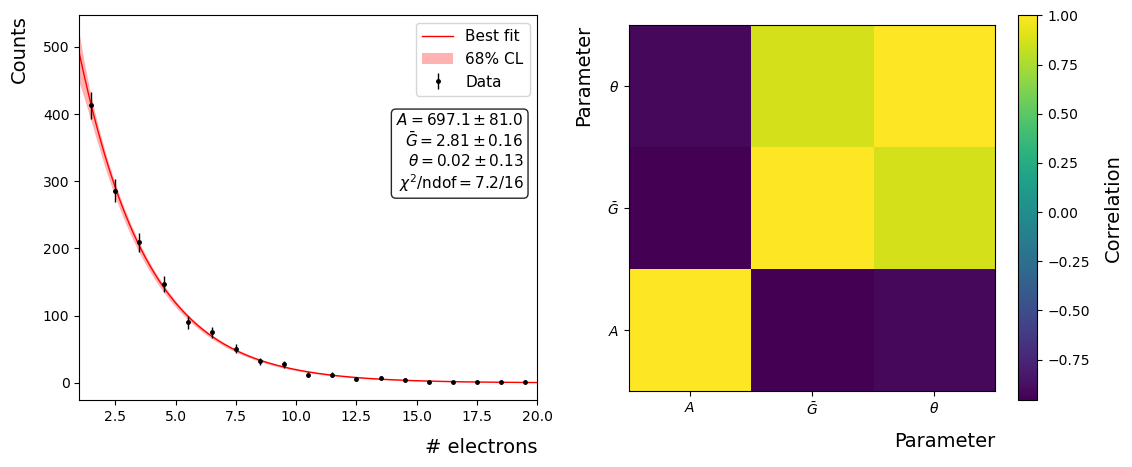

In [60]:
# Make a nice plot
fig = plt.figure(figsize=(13, 5))
gs = fig.add_gridspec(1, 2, wspace=0.20, hspace=0.30)
axs = gs.subplots().ravel()

axs[0].errorbar(x, y, yerr=yerr,
                linestyle="None", elinewidth=1.0,
                marker=".", markersize=5., color="k",
                zorder=100, label="Data")

axs[0].plot(xfit, yfit, color="r", linewidth=1.0, label="Best fit")
axs[0].fill_between(
    xfit,
    ylow,
    yhigh,
    color="r",
    alpha=0.3,
    linewidth=0,
    label="68% CL"
)

axs[0].set_xlim(bins[0], bins[-1])
axs[0].set_xlabel("# electrons", fontsize=14, labelpad=10, loc="right")
axs[0].set_ylabel("Counts", fontsize=14, labelpad=10, loc="top")

axs[0].legend(fontsize=11, loc="upper right")

summary = (
    rf"$A = {A:.1f} \pm {A_err:.1f}$" "\n"
    rf"$\bar{{G}} = {G0:.2f} \pm {G0_err:.2f}$" "\n"
    rf"$\theta = {theta:.2f} \pm {theta_err:.2f}$" "\n"
    rf"$\chi^2/\mathrm{{ndof}} = {chi2:.1f} / {ndof}$"
)

axs[0].text(
    0.97, 0.75, summary,
    transform=axs[0].transAxes,
    fontsize=11,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="black",
        alpha=0.85
    )
)

im = axs[1].imshow(corr, origin="lower")
axs[1].set_xticks(np.arange(3), labels=[r"$A$", r"$\bar{G}$", r"$\theta$"])
axs[1].set_xlabel("Parameter", fontsize=14, labelpad=10, loc="right")
axs[1].set_yticks(np.arange(3), labels=[r"$A$", r"$\bar{G}$", r"$\theta$"])
axs[1].set_ylabel("Parameter", fontsize=14, labelpad=10, loc="top")

cbar = fig.colorbar(im, ax=axs[1])
cbar.set_label("Correlation", fontsize=14, labelpad=10)

plt.show()